# Task 06 — Credit risk across loan vintages: approve, price, and know when the model stops working

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [All Lending Club loan data](https://www.kaggle.com/datasets/wordsforthewise/lending-club) (2.26 M loans issued 2007–2018 with their status in spring 2019, and 27.6 M rejected applications)
**Task family:** tabular supervised learning (probability of default), calibration, cut-off and price from realised economics, vintage validation and drift under years of label delay · **Companion task:** `02_card_fraud_tabular.ipynb` (the same honest evaluation; there the label takes weeks, here three years)

---

## The task card

> **Board question.** *In 2015 we approved about one application in eight, and 14.7 % of the 36-month loans we made in its second half were charged off. Which applicants should we approve, and at what rate, so that a vintage makes money? And since a 36-month loan takes over three years to tell us whether we were right, how do we know within 16 months that the model has stopped working?*

**Business context.** A consumer lender scores each application before making an offer (Session 01's *online prediction*), refers borderline cases to an underwriter (*human-in-the-loop*) and reads each vintage, the loans issued in a quarter, in a monthly *offline batch*. The legacy estate: loan origination, the bureau link, a rules engine with the credit policy, servicing, collections, and the incumbent scorecard (LendingClub's grade, A1–G5, which in this data all but fixes the rate). Every personal-loan desk in Malta takes this decision; what sets credit apart is that today's approval is graded three years from now.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **probability-of-default (PD) model** on application and bureau data, packaged and reproducible, tested on a later matured vintage, calibrated, against the incumbent grade;
2. an **approval cut-off and a price grid** from realised economics, the constants in an ADR;
3. the **operational wrapper**: package, CI gate on a frozen matured vintage, column whitelist, registry, model card, monitoring that warns before the labels exist;
4. a **governance position**: AI Act high-risk, fairness through proxies, a reason for every decline.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Decisioning inside loan origination; incumbent scorecard and rules engine; AI Act high-risk |
| 2 · MLOps | Vintage validation, a gate on AUC and calibration, label delay in years (Session 04), registry and model card (Session 06) |
| 3 · Semantic layer | The credit policy as a small graph: rate grid, purposes, rules with validity dates |
| 4 · LLM/RAG | Reason letters grounded in the model's reasons and the written policy |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**: LendingClub's public loan files, with no names in them, and genuine outcomes and money. It is also a single snapshot of a book still being repaid, with outcomes only for approved loans. Kaggle lists it as CC0, but the uploader warns that LendingClub "now has a scary 'TOS' popup when downloading the data" and might ask for it to be taken down. Study it, cite it, do not redistribute it.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at a book still being repaid | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | The PD model across vintages, the cut-off and price, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | Drift after deployment, governance in production, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the failure your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `read_columns`, `load_accepted`, `load_rejected` and `add_outcomes` (Section 1); `vintage_table` (Section 2); `build_features`, `fit` and `scores` (Section 3); `loan_profit`, `cutoff_curve`, `book_summary` and `band_table` (Section 4); `psi_ref`, `psi` and `psi_cat` for monitoring (Section 6); `slice_table` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 57 features (whitelist sha256 `ca950881a399`); train 262,992 loans (13.2 % bad), validation 120,791 (15.1 %) and test 162,236 (14.7 %); test AUC 0.697 against 0.681 for LendingClub's sub-grade, predicted ÷ realised 0.99 (gate PASS); cut-off PD ≤ 0.249, approving 85.0 % on validation; on the test vintage, profit $33.9 m against $23.3 m for LendingClub's book.
- **Runtime:** about 5 minutes on a laptop (300 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pcsv
import pyarrow.parquet as pq
import duckdb
import lightgbm as lgb
import sklearn
from IPython.display import display
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 140)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "wordsforthewise/lending-club"
N_JOBS = 1                               # LightGBM / scikit-learn threads (raise it on your own laptop)
TERM = "36 months"                       # the product modelled here; 60-month loans are task E3
SNAPSHOT = pd.Timestamp("2019-04-01")    # the extract: the last payment in the file is dated March 2019 (Section 1)
TRAIN_START = pd.Timestamp("2013-01-01") # train: vintages 2013–2014 (bureau fields complete from 2013)
TRAIN_END = pd.Timestamp("2015-01-01")
VALID_END = pd.Timestamp("2015-07-01")   # validation (calibration, cut-off): vintages Jan–Jun 2015
TEST_END = pd.Timestamp("2016-01-01")    # test, the frozen CI holdout: Jul–Dec 2015, matured before the snapshot
STREAM_END = pd.Timestamp("2019-01-01")  # production stream: vintages 2016–2018, outcomes still arriving
REFIT_DATE = pd.Timestamp("2017-07-01")  # Trap 2: a committee refits the model with what it could see that day
CHARGEOFF_LAG_M = 5                      # months from the last payment to charge-off (approximation for rewinding the clock)
EPD_MONTHS = 12                          # early-performance proxy: stopped paying within the first 12 months
COST_OF_FUNDS = 0.04                     # a year, on the average balance outstanding (assumption — task C3)
SERVICING_FEE = 0.01                     # share of every payment collected (assumption — task C3)
GATE_MIN_AUC = 0.68                      # CI gate on the frozen holdout (placeholder for the credit committee's number)
CALIBRATION_BAND = (0.90, 1.10)          # predicted ÷ realised defaults on the holdout must fall inside
EPD_ALERT = 1.15                         # early warning on observed ÷ expected early defaults (placeholder for the committee)
SIM_FICO_FLOOR = 700                     # Trap 3: a stricter incumbent policy, simulated on the approved loans

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "lending_club", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"numpy {np.__version__} · pyarrow {pa.__version__} · duckdb {duckdb.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4 · pyarrow 26.0.0 · duckdb 2.0.0


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `load_accepted`, `load_rejected` and `add_outcomes`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `wordsforthewise/lending-club` (Nathan George's merge of the loan files LendingClub published on its site) |
| **Licence** | CC0 on Kaggle; the uploader warns that LendingClub may object to redistribution |
| **Provenance** | Real loans from LendingClub, a US lender (`addr_state` holds US states), published by the lender; one snapshot from spring 2019 (last payment March 2019) |
| **Size** | Accepted: 2,260,668 loans, 151 columns, issued Jun 2007 – Dec 2018. Rejected: 27,648,741 applications, 9 columns, May 2007 – Dec 2018 |
| **Files** | `accepted_2007_to_2018Q4.csv.gz` (393 MB), `rejected_2007_to_2018Q4.csv.gz` (256 MB) |
| **Schema (accepted)** | Application (amount, term, purpose, employment, housing, income, DTI); bureau at application (FICO, about 50 counts and balances); LendingClub's decision (grade, rate); the loan's life so far (payments, recoveries, `loan_status`) |
| **Label** | `bad` = charged off or in default; 14.7 % of the 36-month loans issued Jul–Dec 2015 |
| **Window used here** | 36-month loans issued 2013–2018 (1.53 M): train 2013–2014, validate Jan–Jun 2015, test Jul–Dec 2015, stream 2016–2018. 205 MB Parquet cache; about 2 GB of RAM at peak (lower `STREAM_END` on a small laptop) |
| **PII** | No names. Ids, the listing URL, job title, loan title and description (free text) and the 3-digit zip are never read; `addr_state` is kept for fairness slices only |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **A snapshot of a book still being repaid.** 40.4 % of accepted loans were still open in spring 2019; 36-month vintages are complete only up to 2015 Q4, 60-month ones up to 2013 Q4 (Section 2).
2. ⚠ **The outcome sits in the application's row.** Payments, recoveries, last-payment and credit-pull dates, last FICO and the settlement flag came after the loan was made (Trap 1).
3. ⚠ **Only approved applicants have outcomes.** The rejected file has six usable fields; only 18 % of 2015 rejections carry a `Risk_Score`, whose scale changes in November 2013 (minimum 0 → 441, spread 136 → 64), so scores either side of that month are not comparable (Trap 3).
4. **The schema grows.** Half the 2012 loans lack the bureau balances; five bureau fields start in December 2015; joint applications in late 2015.
5. **The credit policy moves.** Highest accepted DTI: 24 (2009–10), 29 (2011), 34 (2012–13), 39 (2014), then a 999 sentinel; FICO floor 660 from 2009. `educational` all but vanishes after 2010; `wedding` falls from 595 loans (2013) to 8 (2014).
6. **Sentinels and typos.** 135 DTIs of 999 and 2 negative; 1,667 incomes of $0 and one of $110 M.
7. **Missing employment length is a signal.** Missing for 2.8 % of 2010 loans, 8.5 % of 2018; 2013–2014 36-month loans without it defaulted at 19.4 % against 12.8 %.

In [2]:
ACCEPTED, REJECTED = "accepted_2007_to_2018Q4.csv.gz", "rejected_2007_to_2018Q4.csv.gz"
# Columns read from the accepted file. Everything else is never read: the loan id, member id and listing URL
# (identifiers), the borrower's job title, loan title and description (free text written by real people), and the
# 3-digit zip code (a quasi-identifier).
APP_NUM = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "delinq_2yrs", "fico_range_low", "fico_range_high",
           "inq_last_6mths", "mths_since_last_delinq", "mths_since_last_record", "open_acc", "pub_rec", "revol_bal",
           "revol_util", "total_acc", "annual_inc_joint", "dti_joint", "acc_now_delinq", "tot_coll_amt", "tot_cur_bal",
           "total_rev_hi_lim", "acc_open_past_24mths", "avg_cur_bal", "bc_open_to_buy", "bc_util",
           "chargeoff_within_12_mths", "collections_12_mths_ex_med", "delinq_amnt", "mo_sin_old_il_acct",
           "mo_sin_old_rev_tl_op", "mo_sin_rcnt_rev_tl_op", "mo_sin_rcnt_tl", "mort_acc", "mths_since_recent_bc",
           "mths_since_recent_inq", "mths_since_last_major_derog", "num_accts_ever_120_pd", "num_actv_bc_tl",
           "num_actv_rev_tl", "num_bc_sats", "num_bc_tl", "num_il_tl", "num_op_rev_tl", "num_rev_accts",
           "num_rev_tl_bal_gt_0", "num_sats", "num_tl_90g_dpd_24m", "num_tl_op_past_12m", "pct_tl_nvr_dlq",
           "percent_bc_gt_75", "pub_rec_bankruptcies", "tax_liens", "tot_hi_cred_lim", "total_bal_ex_mort",
           "total_bc_limit", "total_il_high_credit_limit", "open_acc_6m", "il_util", "all_util", "inq_last_12m", "inq_fi",
           "policy_code"]
APP_CAT = ["term", "grade", "sub_grade", "emp_length", "home_ownership", "verification_status", "purpose", "addr_state",
           "initial_list_status", "application_type"]
POST_NUM = ["funded_amnt", "funded_amnt_inv", "out_prncp", "total_pymnt", "total_rec_prncp", "total_rec_int",
            "total_rec_late_fee", "recoveries", "collection_recovery_fee", "last_pymnt_amnt", "last_fico_range_high",
            "last_fico_range_low"]
POST_CAT = ["loan_status", "pymnt_plan", "hardship_flag", "debt_settlement_flag"]
DATES = ["issue_d", "earliest_cr_line", "last_pymnt_d", "next_pymnt_d", "last_credit_pull_d"]
OPEN_STATUSES = ["Current", "In Grace Period", "Late (16-30 days)", "Late (31-120 days)"]

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def month(s: pd.Series) -> pd.Series:
    """'Dec-2015' → 2015-12-01, parsing each distinct string once."""
    u = pd.Series(s.unique())
    return s.map(dict(zip(u, pd.to_datetime(u, format="%b-%Y", errors="coerce"))))

def read_columns(path: Path, columns=None, rows=None) -> pd.DataFrame:
    """Read a Parquet file one column at a time (peak ≈ the result, not twice it); `rows` is an optional boolean mask."""
    pf, out = pq.ParquetFile(path), {}
    keep = None if rows is None else pa.array(rows)
    for c in columns or pf.schema_arrow.names:
        col = pf.read(columns=[c]).column(0)
        s = (col if keep is None else col.filter(keep)).to_pandas()
        out[c] = s.astype("category") if c in APP_CAT + POST_CAT else s
    return pd.DataFrame(out, copy=False)

def load_accepted(columns=None, rows=None) -> pd.DataFrame:
    cache = PROCESSED / "06_lending_club_accepted.parquet"
    if not cache.exists():          # stream the 1.7 GB CSV in 32 MB blocks; the whole text never sits in memory
        t = time.time()
        types = {c: pa.float32() for c in APP_NUM + POST_NUM} | {c: pa.string() for c in APP_CAT + POST_CAT + DATES}
        reader = pcsv.open_csv(get_raw(ACCEPTED), read_options=pcsv.ReadOptions(block_size=1 << 25),
                               convert_options=pcsv.ConvertOptions(include_columns=list(types), column_types=types))
        tmp, writer = cache.with_suffix(".tmp"), None
        for batch in reader:
            d = batch.to_pandas()
            d = d[d.loan_amnt.notna()]                       # the 'Total amount funded in policy code …' footer rows
            for c in DATES:
                d[c] = month(d[c]).astype("datetime64[s]")
            for c in APP_CAT + POST_CAT:
                d[c] = d[c].str.strip()
            tbl = pa.Table.from_pandas(d, preserve_index=False)
            writer = writer or pq.ParquetWriter(tmp, tbl.schema, compression="zstd")
            writer.write_table(tbl)
        writer.close(); tmp.replace(cache)
        print(f"accepted: streamed + cached in {time.time()-t:.0f}s")
    return read_columns(cache, columns, rows)

def load_rejected() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Exact monthly counts of rejected applications plus a deterministic 1-in-50 sample, both via DuckDB."""
    cache, cache_m = PROCESSED / "06_lending_club_rejected_sample.parquet", PROCESSED / "06_lending_club_rejected_monthly.parquet"
    if not (cache.exists() and cache_m.exists()):
        t = time.time()
        con = duckdb.connect()
        con.execute("SET memory_limit='1GB'; SET threads=2; SET enable_progress_bar=false;")
        src = "read_csv('{}', header=true, all_varchar=true)".format(str(get_raw(REJECTED)).replace("'", "''"))
        con.execute(f"""SELECT date_trunc('month', CAST("Application Date" AS DATE)) AS month, count(*) AS rejected
                        FROM {src} GROUP BY 1 ORDER BY 1""").df().to_parquet(cache_m)
        con.execute(f"""SELECT CAST("Application Date" AS DATE) AS app_date, CAST("Amount Requested" AS FLOAT) AS amount,
                               CAST("Risk_Score" AS FLOAT) AS risk_score,
                               TRY_CAST(REPLACE("Debt-To-Income Ratio", '%', '') AS FLOAT) AS dti,
                               "State" AS state, "Employment Length" AS emp_length
                        FROM {src}
                        WHERE hash("Application Date" || "Amount Requested" || coalesce("Zip Code", '')) % 50 = 0
                     """).df().to_parquet(cache)           # zip code is used only inside the hash, never stored
        print(f"rejected: counted, sampled + cached in {time.time()-t:.0f}s")
    return pd.read_parquet(cache), pd.read_parquet(cache_m)

mi = lambda s: s.dt.year * 12 + s.dt.month - 1                # month index of a date column

def add_outcomes(d: pd.DataFrame) -> pd.DataFrame:
    """The label, and the two clocks every loan carries. Outcome columns: never features."""
    status = d.loan_status.astype(str)
    d["bad"] = (status.str.contains("Charged Off") | (status == "Default")).astype("int8")    # charged off or in default
    d["is_open"] = status.isin(OPEN_STATUSES)                                                   # outcome still unknown
    d["mob_last"] = (mi(d.last_pymnt_d) - mi(d.issue_d)).fillna(0).astype("int16")             # months on book at last payment
    d["epd"] = (((d.bad == 1) | (status == "Late (31-120 days)")) & (d.mob_last <= EPD_MONTHS)).astype("int8")
    d["vintage"] = d.issue_d.dt.to_period("Q")
    return d

BOOK = ["issue_d", "term", "loan_status", "last_pymnt_d", "last_credit_pull_d", "next_pymnt_d", "dti", "fico_range_low",
        "annual_inc", "purpose", "emp_length", "tot_cur_bal", "open_acc_6m", "il_util", "all_util", "inq_last_12m", "inq_fi",
        "annual_inc_joint"]
book = add_outcomes(load_accepted(BOOK))          # every accepted loan, only the columns the vintage view needs
rejected, rejected_monthly = load_rejected()
print(f"{len(book):,} accepted loans issued {book.issue_d.min():%b %Y} – {book.issue_d.max():%b %Y} · "
      f"{book.is_open.mean():.1%} still open at the snapshot · {pq.ParquetFile(PROCESSED / '06_lending_club_accepted.parquet').metadata.num_columns} "
      f"columns kept of 151 ({(PROCESSED / '06_lending_club_accepted.parquet').stat().st_size / 1e6:.0f} MB cache) · "
      f"{rejected_monthly.rejected.sum():,} rejected applications ({len(rejected):,} sampled)")

2,260,668 accepted loans issued Jun 2007 – Dec 2018 · 40.4% still open at the snapshot · 94 columns kept of 151 (205 MB cache) · 27,648,741 rejected applications (555,430 sampled)


In [3]:
# Every number in the dataset card comes from this cell or a later one
print(f"latest dates in the file: last payment {book.last_pymnt_d.max():%b %Y} · last credit pull "
      f"{book.last_credit_pull_d.max():%b %Y} · next payment due {book.next_pymnt_d.max():%b %Y}")
display(pd.crosstab(book.issue_d.dt.year, book.term).T)
print("final status:", book.loan_status.value_counts().to_dict())
yr = book.issue_d.dt.year
newer = ["tot_cur_bal", "open_acc_6m", "all_util", "inq_last_12m", "annual_inc_joint"]
display(book[newer].notna().groupby(yr).mean().loc[2011:].T.round(2))
print("first issue month with a value:", {c: f"{book.issue_d[book[c].notna()].min():%b %Y}"
      for c in ["open_acc_6m", "il_util", "all_util", "inq_last_12m", "inq_fi", "annual_inc_joint"]})
print("maximum DTI accepted, by year:", book.dti.groupby(yr).max().astype(int).to_dict())
print("minimum FICO (range low), by year:", book.fico_range_low.groupby(yr).min().astype(int).to_dict())
print(f"DTI sentinels: {int((book.dti == 999).sum()):,} at 999, {int((book.dti < 0).sum())} negative · "
      f"annual income 0: {int((book.annual_inc == 0).sum())} · maximum ${book.annual_inc.max():,.0f}")
print("purpose 'educational' by year:", book[book.purpose == "educational"].groupby(yr).size().to_dict(),
      "· 'wedding':", book[book.purpose == "wedding"].groupby(yr).size().loc[2012:].to_dict())
emp_missing = book.emp_length.astype(str) == ""
print("employment length missing, by year:", emp_missing.groupby(yr).mean().round(3).loc[2010:].to_dict())
w = (book.term == TERM) & yr.between(2013, 2014)
print(f"default rate, 36-month loans 2013–2014: employment length missing {book.bad[w & emp_missing].mean():.1%} "
      f"vs given {book.bad[w & ~emp_missing].mean():.1%}")
print(f"'Does not meet the credit policy' loans: {int(book.loan_status.astype(str).str.startswith('Does not').sum()):,} "
      f"(issued {book.issue_d[book.loan_status.astype(str).str.startswith('Does not')].min():%Y}–{book.issue_d[book.loan_status.astype(str).str.startswith('Does not')].max():%Y})")
rj = rejected.assign(year=rejected.app_date.dt.year)
print("rejected file: share with a Risk_Score, by year:", rj.groupby("year").risk_score.apply(lambda s: s.notna().mean()).round(2).to_dict())
br = rj[(rj.app_date >= "2013-09-01") & (rj.app_date < "2014-01-01")].groupby(rj.app_date.dt.to_period("M")).risk_score
print("Risk_Score around Nov 2013 (min / std):", {str(k): (int(v.min()), int(v.std())) for k, v in br})
del emp_missing, rj, br

latest dates in the file: last payment Mar 2019 · last credit pull Apr 2019 · next payment due May 2019


issue_d,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
term,,,,,,,,,,,,
36 months,603,2393,5281,9156,14101,43470,100422,162570,283173,323495,320419,344671
60 months,0,0,0,3381,7620,9897,34392,73059,137922,110912,123160,150571


final status: {'Fully Paid': 1076751, 'Current': 878317, 'Charged Off': 268559, 'Late (31-120 days)': 21467, 'In Grace Period': 8436, 'Late (16-30 days)': 4349, 'Does not meet the credit policy. Status:Fully Paid': 1988, 'Does not meet the credit policy. Status:Charged Off': 761, 'Default': 40}


issue_d,2011,2012,2013,2014,2015,2016,2017,2018
tot_cur_bal,0.0,0.48,1.0,1.0,1.00,1.00,1.0,1.00
open_acc_6m,0.0,0.00,0.0,0.0,0.05,1.00,1.0,1.00
all_util,0.0,0.00,0.0,0.0,0.05,1.00,1.0,1.00
inq_last_12m,0.0,0.00,0.0,0.0,0.05,1.00,1.0,1.00
annual_inc_joint,0.0,0.00,0.0,0.0,0.00,0.02,0.1,0.14


first issue month with a value: {'open_acc_6m': 'Dec 2015', 'il_util': 'Dec 2015', 'all_util': 'Dec 2015', 'inq_last_12m': 'Dec 2015', 'inq_fi': 'Dec 2015', 'annual_inc_joint': 'Oct 2015'}


maximum DTI accepted, by year: {2007: 28, 2008: 29, 2009: 24, 2010: 24, 2011: 29, 2012: 34, 2013: 34, 2014: 39, 2015: 999, 2016: 999, 2017: 999, 2018: 999}
minimum FICO (range low), by year: {2007: 610, 2008: 635, 2009: 660, 2010: 660, 2011: 660, 2012: 660, 2013: 660, 2014: 660, 2015: 660, 2016: 660, 2017: 660, 2018: 660}


DTI sentinels: 135 at 999, 2 negative · annual income 0: 1667 · maximum $110,000,000
purpose 'educational' by year: {2007: 36, 2008: 85, 2009: 187, 2010: 114, 2015: 1, 2017: 1} · 'wedding': {2012: 736, 2013: 595, 2014: 8, 2015: 4, 2016: 2, 2017: 1, 2018: 5}


employment length missing, by year: {2010: 0.028, 2011: 0.035, 2012: 0.036, 2013: 0.044, 2014: 0.051, 2015: 0.057, 2016: 0.065, 2017: 0.072, 2018: 0.085}
default rate, 36-month loans 2013–2014: employment length missing 19.4% vs given 12.8%


'Does not meet the credit policy' loans: 2,749 (issued 2007–2010)


rejected file: share with a Risk_Score, by year: {2007: 0.99, 2008: 0.9, 2009: 0.88, 2010: 0.93, 2011: 0.99, 2012: 0.99, 2013: 0.97, 2014: 0.87, 2015: 0.18, 2016: 0.22, 2017: 0.55, 2018: 0.07}


Risk_Score around Nov 2013 (min / std): {'2013-09': (0, 175), '2013-10': (0, 136), '2013-11': (441, 64), '2013-12': (471, 65)}


## 2 · First look: a book that has not finished paying

*Part A · Explore · read; package `vintage_table`; unfinished vintages are why labels arrive years late.*

Before any model: how much of the book has an answer yet, and what does it look like if read too early?

,loans,open_at_snapshot,bad_open_as_good,bad_resolved_only
vintage,,,,
2013Q1,"17,988",0.0%,12.6%,12.6%
2014Q4,"50,020",0.0%,14.5%,14.5%
2015Q2,"64,222",0.0%,15.4%,15.4%
2015Q4,"88,810",0.2%,14.8%,14.8%
2016Q1,"96,120",6.6%,15.0%,16.1%
2016Q3,"73,898",36.2%,14.6%,22.8%
2017Q2,"77,105",55.7%,9.3%,20.9%
2017Q4,"82,677",69.9%,5.4%,17.9%
2018Q2,"91,506",85.2%,2.2%,15.1%


,2012,2013,2014,2015,2016,2017,2018
accepted,"53,367","134,814","235,629","421,095","434,407","443,579","495,242"
rejected,"337,277","760,942","1,933,700","2,859,379","4,769,874","7,072,573","9,496,782"
approval_rate,13.7%,15.1%,10.9%,12.8%,8.3%,5.9%,5.0%


60-month loans: the last vintage with < 1 % still open is 2013Q4
2015 → 2018: rejected applications ×3.3, accepted loans +18%


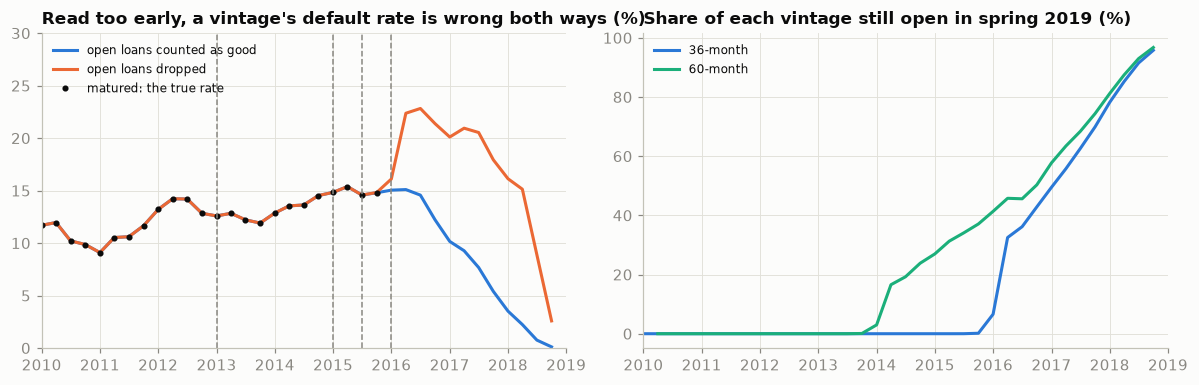

In [4]:
# Approval funnel: accepted ÷ (accepted + rejected), by year
acc_y = book.groupby(yr).size()
rej_y = rejected_monthly.groupby(rejected_monthly.month.dt.year).rejected.sum()
funnel = pd.DataFrame({"accepted": acc_y, "rejected": rej_y}).assign(approval_rate=lambda d: d.accepted / (d.accepted + d.rejected))
acc_q = book.groupby("vintage").size()
rej_q = rejected_monthly.groupby(rejected_monthly.month.dt.to_period("Q")).rejected.sum()
approval_q = (acc_q / (acc_q + rej_q)).rename("approval_rate")

# Vintage table: three ways to read the default rate of a quarter's loans, by term
def vintage_table(d):
    g = d.groupby("vintage", observed=True)
    t = pd.DataFrame({"loans": g.size(), "open_at_snapshot": g["is_open"].mean(),
                      "bad_open_as_good": g.bad.mean()})                       # naive A: open loans count as good
    t["bad_resolved_only"] = d[~d.is_open].groupby("vintage", observed=True).bad.mean()   # naive B: drop open loans
    return t
VCOLS = ["vintage", "is_open", "bad"]
v36 = vintage_table(book.loc[book.term == TERM, VCOLS])
v60 = vintage_table(book.loc[book.term == "60 months", VCOLS])
matured36 = v36.open_at_snapshot < 0.01

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
x = v36.index.to_timestamp()
ax.plot(x, v36.bad_open_as_good * 100, lw=2, color=SERIES[0], label="open loans counted as good")
ax.plot(x, v36.bad_resolved_only * 100, lw=2, color=SERIES[1], label="open loans dropped")
ax.plot(x[matured36.values], v36.bad_open_as_good[matured36] * 100, "o", ms=3, color=INK, label="matured: the true rate")
for t_ in [TRAIN_START, TRAIN_END, VALID_END, TEST_END]:
    ax.axvline(t_, color=MUTED, ls="--", lw=1)
ax.set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2019-01-01")); ax.set_ylim(0, 30)
ax.set_title("Read too early, a vintage's default rate is wrong both ways (%)"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.plot(x, v36.open_at_snapshot * 100, lw=2, color=SERIES[0], label="36-month")
ax.plot(v60.index.to_timestamp(), v60.open_at_snapshot * 100, lw=2, color=SERIES[2], label="60-month")
ax.set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2019-01-01"))
ax.set_title("Share of each vintage still open in spring 2019 (%)"); ax.legend(fontsize=8)
plt.tight_layout()

show_q = ["2013Q1", "2014Q4", "2015Q2", "2015Q4", "2016Q1", "2016Q3", "2017Q2", "2017Q4", "2018Q2"]
display(v36.loc[pd.PeriodIndex(show_q, freq="Q")].style.format({"loans": "{:,}", "open_at_snapshot": "{:.1%}",
        "bad_open_as_good": "{:.1%}", "bad_resolved_only": "{:.1%}"}))
display(funnel.loc[2012:].T.style.format("{:,.0f}").format("{:.1%}", subset=pd.IndexSlice["approval_rate", :]))
print(f"60-month loans: the last vintage with < 1 % still open is {v60.index[v60.open_at_snapshot < 0.01].max()}")
print(f"2015 → 2018: rejected applications ×{funnel.rejected[2018] / funnel.rejected[2015]:.1f}, "
      f"accepted loans {funnel.accepted[2018] / funnel.accepted[2015] - 1:+.0%}")

Read the left panel from right to left. Up to 2015 Q4 the lines agree: those loans have finished, and the dots are true rates (12.6 % for 2013 Q1, 15.4 % for 2015 Q2). From 2016 the readings split: counting open loans as good gives 2018 Q2 2.2 %, dropping them 15.1 % (22.8 % for 2016 Q3). The true number does not exist yet. And the funnel: rejections grew 3.3-fold from 2015 to 2018, approvals by 18 %, so the approval rate fell from 12.8 % to 5.0 %. Those with outcomes are a shrinking slice of those who asked.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The model: what the application knew, forward across vintages

*Part B · Given model · package `build_features`, `fit` and `scores` unchanged and reproduce the numbers (C2).*

One rule for every column: **a feature may only hold what was known when the credit decision was taken.** The grade, rate and instalment *are* the incumbent's decision, and the rate is the price this model must set (Trap 4); state only slices the errors (Section 7).

The design follows the clock: train on the 2013–2014 vintages, calibrate and choose the cut-off on Jan–Jun 2015, test on Jul–Dec 2015 (all finished); 2016–2018 is the production stream. This is a **backtest**: the last 2014 loans finished in early 2018, so this model could not exist earlier (Trap 2). Metrics: **AUC** for ranking (Gini = 2·AUC − 1, the committee's number) and **predicted ÷ realised** defaults, because price and expected loss depend on the PD's level.

In [5]:
# As-of rule, column by column (what exists at the moment the credit decision is taken?)
AS_OF = {
    "application and credit bureau, at application": "kept: the feature whitelist below",
    "decided by the incumbent's process (grade, sub_grade, int_rate, installment, verification_status, initial_list_status)": "excluded: the old model's output and the price being decided (Trap 4)",
    "geography (addr_state)": "excluded from features; used for fairness slices (Section 7)",
    "after origination (payments, recoveries, last_* dates, last FICO, hardship, settlement, loan_status)": "excluded: the outcome (Trap 1)",
    "bureau fields added in Dec 2015 (open_acc_6m, il_util, all_util, inq_last_12m, inq_fi) and joint-application fields": "excluded: absent from every training vintage",
}
FEAT_NUM = ["loan_amnt", "annual_inc", "dti", "inq_last_6mths", "delinq_2yrs", "mths_since_last_delinq",
            "mths_since_last_record", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "acc_now_delinq",
            "tot_coll_amt", "tot_cur_bal", "total_rev_hi_lim", "acc_open_past_24mths", "avg_cur_bal", "bc_open_to_buy",
            "bc_util", "chargeoff_within_12_mths", "collections_12_mths_ex_med", "delinq_amnt", "mo_sin_old_il_acct",
            "mo_sin_old_rev_tl_op", "mo_sin_rcnt_rev_tl_op", "mo_sin_rcnt_tl", "mort_acc", "mths_since_recent_bc",
            "mths_since_recent_inq", "mths_since_last_major_derog", "num_accts_ever_120_pd", "num_actv_bc_tl",
            "num_actv_rev_tl", "num_bc_sats", "num_bc_tl", "num_il_tl", "num_op_rev_tl", "num_rev_accts",
            "num_rev_tl_bal_gt_0", "num_sats", "num_tl_90g_dpd_24m", "num_tl_op_past_12m", "pct_tl_nvr_dlq",
            "percent_bc_gt_75", "pub_rec_bankruptcies", "tax_liens", "tot_hi_cred_lim", "total_bal_ex_mort",
            "total_bc_limit", "total_il_high_credit_limit"]
FEAT_CAT = ["emp_length", "home_ownership", "purpose"]
FEATURES = FEAT_NUM + ["fico", "credit_history_m", "loan_to_income"] + FEAT_CAT
WHITELIST_SHA = hashlib.sha256(",".join(FEATURES).encode()).hexdigest()[:12]
display(pd.Series(AS_OF, name="decision").rename_axis("columns").to_frame())

# From here on: every column, for 36-month loans issued 2013–2018 only
in_scope = ((book.term == TERM) & (book.issue_d >= TRAIN_START) & (book.issue_d < STREAM_END)).values
loans = add_outcomes(load_accepted(rows=in_scope))
del book

def build_features(d: pd.DataFrame) -> pd.DataFrame:
    X = d[FEAT_NUM].copy()
    X["dti"] = d.dti.where((d.dti >= 0) & (d.dti < 999))                    # 999 and -1 are sentinels
    X["fico"] = (d.fico_range_low + d.fico_range_high) / 2
    X["credit_history_m"] = ((d.issue_d - d.earliest_cr_line).dt.days / 30.44).astype("float32")
    X["loan_to_income"] = (d.loan_amnt / d.annual_inc.where(d.annual_inc > 0)).astype("float32")
    for c in FEAT_CAT:
        X[c] = d[c].astype(str).replace({"": "missing"}).astype("category")
    return X[FEATURES]

X = build_features(loans)
y = loans.bad.values
tr = ((loans.issue_d < TRAIN_END)).values
va = ((loans.issue_d >= TRAIN_END) & (loans.issue_d < VALID_END)).values
te = ((loans.issue_d >= VALID_END) & (loans.issue_d < TEST_END) & ~loans.is_open).values   # matured loans only
st = (loans.issue_d >= TEST_END).values                                                  # the production stream
print(f"{len(FEATURES)} features (whitelist sha256 {WHITELIST_SHA}) · train {tr.sum():,} loans, {y[tr].mean():.1%} bad · "
      f"valid {va.sum():,}, {y[va].mean():.1%} · test {te.sum():,}, {y[te].mean():.1%} "
      f"({int(((loans.issue_d >= VALID_END) & (loans.issue_d < TEST_END) & loans.is_open).sum())} still open, excluded) · "
      f"stream {st.sum():,}")

,decision
columns,
"application and credit bureau, at application",kept: the feature whitelist below
"decided by the incumbent's process (grade, sub_grade, int_rate, installment, verification_status, initial_list_status)",excluded: the old model's output and the price being decided (Trap 4)
geography (addr_state),excluded from features; used for fairness slices (Section 7)
"after origination (payments, recoveries, last_* dates, last FICO, hardship, settlement, loan_status)",excluded: the outcome (Trap 1)
"bureau fields added in Dec 2015 (open_acc_6m, il_util, all_util, inq_last_12m, inq_fi) and joint-application fields",excluded: absent from every training vintage


57 features (whitelist sha256 ca950881a399) · train 262,992 loans, 13.2% bad · valid 120,791, 15.1% · test 162,236, 14.7% (146 still open, excluded) · stream 988,585


In [6]:
LGB_PARAMS = dict(n_estimators=150, learning_rate=0.08, num_leaves=31, max_bin=63, min_child_samples=300, subsample=0.7,
                  subsample_freq=1, colsample_bytree=0.6, reg_lambda=5.0, random_state=SEED, verbose=-1, n_jobs=N_JOBS)
AUX_PARAMS = LGB_PARAMS | dict(n_estimators=80, learning_rate=0.12, num_leaves=15, subsample=0.5)   # smaller: the trap demos

def fit(Xf, yf, params=LGB_PARAMS):
    return lgb.LGBMClassifier(**params).fit(Xf, yf)

def scores(yt, p):
    return {"AUC": roc_auc_score(yt, p), "Gini": 2 * roc_auc_score(yt, p) - 1, "predicted ÷ realised": p.mean() / yt.mean()}

t0 = time.time()
model = fit(X[tr], y[tr])
fit_s = time.time() - t0
p_raw = model.predict_proba(X)[:, 1]                       # every 36-month loan 2013–2018, frozen model
calib = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=0.999).fit(p_raw[va], y[va])
pd_ = calib.predict(p_raw)                                  # the calibrated probability of default (PD)

# logistic scorecard on the same whitelist: the transparent comparison
rows_lr = tr | te
Xl = X.loc[rows_lr, FEAT_NUM + ["fico", "credit_history_m", "loan_to_income"]].copy()
for c in Xl.columns:
    if Xl[c].max() > 1000:                                   # money amounts and balances: log scale
        Xl[c] = np.log1p(Xl[c].clip(lower=0))
Xl = Xl.fillna(Xl[tr[rows_lr]].median())
Xl = pd.concat([Xl, pd.get_dummies(X.loc[rows_lr, FEAT_CAT], dtype="float32")], axis=1)
scorecard = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=300)).fit(Xl[tr[rows_lr]], y[tr])
p_lr_te = scorecard.predict_proba(Xl[te[rows_lr]])[:, 1]
del Xl

sub = loans.sub_grade.cat.codes.values.astype(float)
res = pd.DataFrame({
    "LightGBM, raw": scores(y[te], p_raw[te]),
    "LightGBM, calibrated on 2015 H1": scores(y[te], pd_[te]),
    "logistic scorecard, raw": scores(y[te], p_lr_te),
    "LC sub-grade (the incumbent)": {"AUC": roc_auc_score(y[te], sub[te]), "Gini": 2 * roc_auc_score(y[te], sub[te]) - 1,
                                     "predicted ÷ realised": np.nan},
}).T
res["Brier"] = [brier_score_loss(y[te], p) for p in [p_raw[te], pd_[te], p_lr_te]] + [np.nan]
print(f"LightGBM fit {fit_s:.0f}s · test vintage Jul–Dec 2015: {te.sum():,} matured loans, {y[te].mean():.2%} defaulted")
display(res.style.format({"AUC": "{:.3f}", "Gini": "{:.3f}", "predicted ÷ realised": "{:.2f}", "Brier": "{:.4f}"}, na_rep="—"))

# the CI gate, as `make ci` will run it: frozen holdout, fingerprinted, scored on matured loans only
holdout = X[te].reset_index(drop=True).assign(bad=y[te])
HOLDOUT_SHA = hashlib.sha256(pd.util.hash_pandas_object(holdout, index=False).values.tobytes()).hexdigest()[:12]
g_auc, g_cal = res.loc["LightGBM, calibrated on 2015 H1", ["AUC", "predicted ÷ realised"]]
ok = g_auc >= GATE_MIN_AUC and CALIBRATION_BAND[0] <= g_cal <= CALIBRATION_BAND[1]
print(f"gate · holdout sha256 {HOLDOUT_SHA} · AUC {g_auc:.3f} (≥ {GATE_MIN_AUC}) · predicted ÷ realised {g_cal:.2f} "
      f"(inside {CALIBRATION_BAND[0]}–{CALIBRATION_BAND[1]}) → {'PASS' if ok else 'FAIL'}")
del holdout

LightGBM fit 22s · test vintage Jul–Dec 2015: 162,236 matured loans, 14.71% defaulted


,AUC,Gini,predicted ÷ realised,Brier
"LightGBM, raw",0.697,0.395,0.91,0.1177
"LightGBM, calibrated on 2015 H1",0.697,0.394,0.99,0.1175
"logistic scorecard, raw",0.689,0.378,0.91,0.1185
LC sub-grade (the incumbent),0.681,0.363,—,—


gate · holdout sha256 7cc5b73cecfc · AUC 0.697 (≥ 0.68) · predicted ÷ realised 0.99 (inside 0.9–1.1) → PASS


gain share, top 6: {'fico': '11.7%', 'loan_to_income': '6.2%', 'annual_inc': '6.1%', 'acc_open_past_24mths': '6.0%', 'bc_open_to_buy': '5.4%', 'dti': '5.1%'}


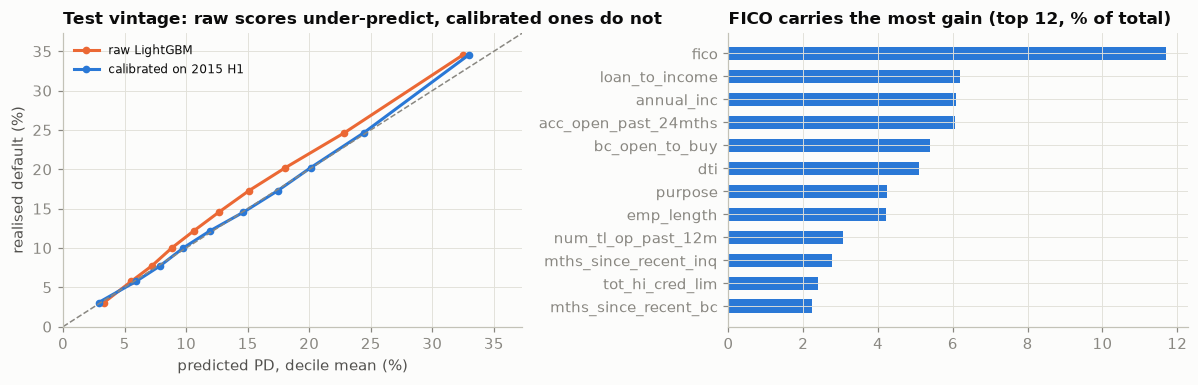

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
dec = pd.qcut(pd_[te], 10, labels=False, duplicates="drop")
rel = pd.DataFrame({"dec": dec, "p_raw": p_raw[te], "pd": pd_[te], "y": y[te]}).groupby("dec").mean()
ax.plot(rel.p_raw * 100, rel.y * 100, "-o", ms=4, lw=2, color=SERIES[1], label="raw LightGBM")
ax.plot(rel.pd * 100, rel.y * 100, "-o", ms=4, lw=2, color=SERIES[0], label="calibrated on 2015 H1")
lim = max(rel.y.max(), rel.pd.max()) * 100 * 1.08
ax.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("predicted PD, decile mean (%)"); ax.set_ylabel("realised default (%)")
ax.set_title("Test vintage: raw scores under-predict, calibrated ones do not"); ax.legend(fontsize=8)
ax = axes[1]
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False).head(12)
ax.barh(imp.index[::-1], imp.values[::-1] * 100, color=SERIES[0], height=0.6)
ax.set_title("FICO carries the most gain (top 12, % of total)")
plt.tight_layout()
print("gain share, top 6:", {k: f"{v:.1%}" for k, v in imp.head(6).items()})

On application and bureau data alone, the model ranks better than LendingClub's own sub-grade: AUC 0.697 against 0.681 (Gini 0.395 against 0.363). A logistic scorecard on the same whitelist reaches 0.689, half the gap; remember that when the regulator asks why you need gradient boosting. Raw scores under-predict the test vintage (0.91) because default rates rose from 13.2 % in training to 15.1 % in validation; isotonic calibration on 2015 H1 brings it to 0.99, and the gate passes. FICO carries 12 % of the gain, followed by affordability (loan-to-income, income) and appetite for credit (accounts opened in 24 months), about 6 % each.

## 4 · The operating point: a cut-off, its expected loss and a price

*Part B · Given model · package `loan_profit`, `cutoff_curve` and `band_table`; C3 asks you to own the constants.*

We choose the cut-off on the **validation vintage**, from what each loan actually paid back (outcome columns may evaluate matured loans; they never become features):

- **profit** = cash collected − amount lent − funding (`COST_OF_FUNDS` a year on half the amount while out) − servicing (`SERVICING_FEE` of each payment); both rates are assumptions (task C3);
- **expected loss** = PD × LGD × amount, LGD (share of a defaulted loan never recovered) measured on training defaults.

LGD (unrecovered principal ÷ amount, training defaults) 0.50 · average months outstanding 25.0 · cut-off chosen on validation: PD ≤ 0.249, approving 85.0%


,loans,approved share,default rate,expected loss $m (PD × LGD × amount),realised principal loss $m,profit $m
approve all (LC's book),"162,236",100.0%,14.71%,144.2,152.1,23.3
model: PD ≤ 24.9%,"145,342",89.6%,12.58%,112.1,114.6,33.9
"LC sub-grade, same volume","145,342",89.6%,12.91%,119.0,115.5,27.2


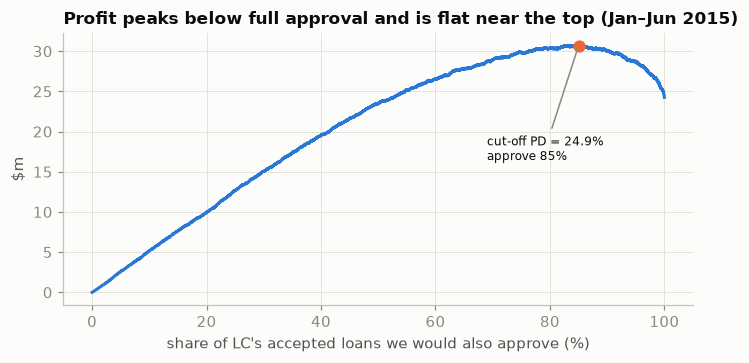

In [8]:
def loan_profit(d: pd.DataFrame) -> np.ndarray:
    """Realised profit of a matured loan, in $: cash collected − amount lent − funding − servicing.
    Funding is charged on half the amount for the months the money was out (a straight-line approximation)."""
    months_out = np.where(d.bad == 1, d.mob_last + CHARGEOFF_LAG_M, d.mob_last).clip(1, 36)
    funding = COST_OF_FUNDS * 0.5 * d.funded_amnt * months_out / 12
    return (d.total_pymnt - d.funded_amnt - funding - SERVICING_FEE * d.total_pymnt).values

profit = np.full(len(loans), np.nan)
matured = tr | va | te
profit[matured] = loan_profit(loans[matured])
amount = loans.funded_amnt.values
bad_tr = tr & (y == 1)
LGD = float(1 - ((loans.total_rec_prncp + loans.recoveries) / loans.funded_amnt)[bad_tr].mean())   # unrecovered principal
LIFE_Y = float(np.where(y == 1, loans.mob_last + CHARGEOFF_LAG_M, loans.mob_last)[tr].clip(1, 36).mean() / 12)

def cutoff_curve(mask):
    o = np.argsort(pd_[mask])
    return pd.DataFrame({"pd": pd_[mask][o], "approved_share": np.arange(1, mask.sum() + 1) / mask.sum(),
                         "profit": np.cumsum(profit[mask][o]), "defaults": np.cumsum(y[mask][o])})
cv = cutoff_curve(va)
best = cv.loc[cv.profit.idxmax()]
PD_CUTOFF = float(best.pd)

def book_summary(mask, approve):
    a = mask & approve
    return {"loans": int(a.sum()), "approved share": a.sum() / mask.sum(), "default rate": y[a].mean(),
            "expected loss $m (PD × LGD × amount)": (pd_[a] * LGD * amount[a]).sum() / 1e6,
            "realised principal loss $m": ((amount - loans.total_rec_prncp.values - loans.recoveries.values) * (y == 1))[a].sum() / 1e6,
            "profit $m": profit[a].sum() / 1e6}

approve_model = pd_ <= PD_CUTOFF
share = (te & approve_model).sum() / te.sum()
# the incumbent at the same volume: best sub-grades first (ties broken at random), same number of loans
rank = np.lexsort((np.random.default_rng(SEED).random(te.sum()), sub[te]))
approve_grade = np.zeros(len(loans), bool)
approve_grade[np.flatnonzero(te)[rank[:(te & approve_model).sum()]]] = True
op = pd.DataFrame({"approve all (LC's book)": book_summary(te, np.ones(len(loans), bool)),
                   f"model: PD ≤ {PD_CUTOFF:.1%}": book_summary(te, approve_model),
                   "LC sub-grade, same volume": book_summary(te, approve_grade)}).T

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(cv.approved_share * 100, cv.profit / 1e6, lw=2, color=SERIES[0])
ax.plot([best.approved_share * 100], [best.profit / 1e6], "o", color=SERIES[1], ms=7)
ax.annotate(f"cut-off PD = {PD_CUTOFF:.1%}\napprove {best.approved_share:.0%}", (best.approved_share * 100, best.profit / 1e6),
            xytext=(-60, -75), textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_xlabel("share of LC's accepted loans we would also approve (%)"); ax.set_ylabel("$m")
ax.set_title("Profit peaks below full approval and is flat near the top (Jan–Jun 2015)")
plt.tight_layout()
print(f"LGD (unrecovered principal ÷ amount, training defaults) {LGD:.2f} · average months outstanding {LIFE_Y*12:.1f} · "
      f"cut-off chosen on validation: PD ≤ {PD_CUTOFF:.3f}, approving {best.approved_share:.1%}")
display(op.style.format({"loans": "{:,.0f}", "approved share": "{:.1%}", "default rate": "{:.2%}",
                         "expected loss $m (PD × LGD × amount)": "{:.1f}", "realised principal loss $m": "{:.1f}",
                         "profit $m": "{:.1f}"}))

In [9]:
# The price: what the rate must cover in each PD band, against what LC charged
bands = pd.cut(pd_, [0, 0.05, 0.10, 0.15, 0.20, 0.30, 1.0], labels=["below 5 %", "5–10 %", "10–15 %", "15–20 %", "20–30 %", "30 % or more"])
months_out = np.where(y == 1, loans.mob_last + CHARGEOFF_LAG_M, loans.mob_last).clip(1, 36)
def band_table(mask):
    return pd.DataFrame({"band": bands[mask], "pd": pd_[mask], "y": y[mask], "rate": loans.int_rate.values[mask] / 100,
                         "profit": profit[mask], "amount": amount[mask],
                         "balance_years": 0.5 * amount[mask] * months_out[mask] / 12}).groupby("band", observed=True).agg(
        loans=("y", "size"), mean_pd=("pd", "mean"), realised_default=("y", "mean"), lc_rate=("rate", "mean"),
        profit=("profit", "sum"), amount=("amount", "sum"), balance_years=("balance_years", "sum"))
pv, pt = band_table(va), band_table(te)
# break-even rate per band, learned on the validation vintage: LC's rate minus the realised margin per $-year outstanding
price = pt[["loans", "mean_pd", "realised_default", "lc_rate"]].copy()
price["break-even rate (from 2015 H1)"] = pv.lc_rate - pv.profit / pv.balance_years
price["realised margin, % of amount"] = pt.profit / pt.amount
display(price.style.format({"loans": "{:,.0f}", "mean_pd": "{:.1%}", "realised_default": "{:.1%}", "lc_rate": "{:.1%}",
                            "break-even rate (from 2015 H1)": "{:.1%}", "realised margin, % of amount": "{:+.1%}"}))

,loans,mean_pd,realised_default,lc_rate,break-even rate (from 2015 H1),"realised margin, % of amount"
band,,,,,,
below 5 %,"20,605",3.1%,3.4%,7.1%,4.8%,+2.3%
5–10 %,"38,193",7.7%,7.6%,9.2%,6.5%,+2.8%
10–15 %,"35,072",12.5%,12.6%,10.9%,8.6%,+2.3%
15–20 %,"26,363",17.5%,17.5%,12.2%,10.9%,+1.1%
20–30 %,"34,038",24.0%,24.4%,13.8%,14.3%,-1.2%
30 % or more,"7,965",35.9%,37.2%,15.9%,21.8%,-7.2%


On the test vintage the cut-off (PD ≤ 24.9 %) keeps 89.6 % of LendingClub's loans, cuts the default rate from 14.7 % to 12.6 % and raises profit from $23.3 m to $33.9 m; declining as many by worst sub-grade makes $27.2 m. Expected loss on the approved loans, $112.1 m, is 2 % below the realised $114.6 m. The price table explains the cut-off: below a PD of 20 % LendingClub's rate beat the break-even learnt on 2015 H1 and earned 1–3 % of the amount; above it the price fell short (13.8 % against 14.3 %, and 15.9 % against 21.8 % for PD ≥ 30 %, a 7.2 % loss). So: decline above the cut-off, price each band at break-even plus a margin. The curve is flat at the top, so the constants matter more than the cut-off (task C3).

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test; Traps 2 and 3 return in E3 and E4.*

Four things a careless version would do, each giving a better-looking number and a worse decision.

**Trap 1 — the outcome in the same row.** Score every column on its own against default on the training vintages:

In [10]:
# Leak scan: how well does each column alone separate defaults on the training vintages?
def single_auc(x, yv):
    m = ~np.isnan(x)
    if m.sum() < 1000 or len(np.unique(yv[m])) < 2:
        return np.nan
    a = roc_auc_score(yv[m], x[m]); return max(a, 1 - a)
POST_DATES = ["last_pymnt_d", "last_credit_pull_d"]
scan = {}
for c in APP_NUM + POST_NUM:
    scan[c] = single_auc(loans[c].values[tr].astype(float), y[tr])
for c in POST_DATES:
    scan[c + " (months after issue)"] = single_auc((mi(loans[c]) - mi(loans.issue_d)).values[tr].astype(float), y[tr])
for c in ["grade", "sub_grade", "debt_settlement_flag", "hardship_flag", "purpose", "home_ownership"]:
    enc = pd.Series(y[tr]).groupby(loans[c].astype(str).values[tr]).transform("mean").values
    scan[c] = single_auc(enc, y[tr])
kind = lambda c: ("after origination ⚠" if c.split(" (")[0] in POST_NUM + POST_CAT + POST_DATES
                  else "incumbent's decision" if c in ["grade", "sub_grade", "int_rate", "installment"] else "application")
scan = pd.DataFrame({"single-column AUC": scan}).assign(when=lambda d: [kind(c) for c in d.index]).sort_values("single-column AUC", ascending=False)
display(scan.head(14).style.format({"single-column AUC": "{:.3f}"}))
print("debt_settlement_flag = Y on training loans:", int((loans.debt_settlement_flag.values[tr] == "Y").sum()),
      "· of which defaulted:", f"{y[tr][loans.debt_settlement_flag.values[tr] == 'Y'].mean():.0%}")
rec = loans.recoveries.values[tr] > 0
print(f"recoveries > 0: {rec[y[tr] == 1].mean():.1%} of defaulted training loans, {rec[y[tr] == 0].mean():.2%} of repaid ones · "
      f"last credit pull as late as {loans.last_credit_pull_d.max():%b %Y}")

LEAKS = ["recoveries", "last_fico_range_low", "total_rec_prncp", "last_pymnt_amnt", "total_pymnt", "collection_recovery_fee"]
X_leak = X.loc[tr | te].copy()
for c in LEAKS:
    X_leak[c] = loans.loc[tr | te, c].values
X_leak["months_to_last_payment"] = loans.mob_last.values[tr | te]
sub_tr, sub_te = tr[tr | te], te[tr | te]
m_leak = fit(X_leak[sub_tr], y[tr], AUX_PARAMS | dict(n_estimators=50))
p_leak = m_leak.predict_proba(X_leak[sub_te])[:, 1]
del X_leak
print(f"test AUC with the post-origination columns ⚠ {roc_auc_score(y[te], p_leak):.3f} · honest whitelist {res.loc['LightGBM, raw', 'AUC']:.3f}")

,single-column AUC,when
recoveries,0.907,after origination ⚠
last_fico_range_low,0.903,after origination ⚠
last_fico_range_high,0.903,after origination ⚠
collection_recovery_fee,0.868,after origination ⚠
total_rec_prncp,0.829,after origination ⚠
last_pymnt_amnt,0.772,after origination ⚠
total_pymnt,0.755,after origination ⚠
last_pymnt_d (months after issue),0.723,after origination ⚠
last_credit_pull_d (months after issue),0.701,after origination ⚠
sub_grade,0.656,incumbent's decision


debt_settlement_flag = Y on training loans: 2903 · of which defaulted: 100%
recoveries > 0: 81.4% of defaulted training loans, 0.00% of repaid ones · last credit pull as late as Apr 2019


test AUC with the post-origination columns ⚠ 0.999 · honest whitelist 0.697


Nine columns beat every honest one, all written after the loan was made: `recoveries` (0.907) is non-zero for 81.4 % of defaulted loans and none of the repaid ones, the last FICO (0.903) comes from pulls as late as April 2019, the months to the last payment (0.723) *is* the default date, and all 2,903 training loans with `debt_settlement_flag = Y` defaulted. The best honest column, FICO at application, scores 0.596. Added to the whitelist, seven of them lift the test AUC to 0.999. The fix is structural: a whitelist (hash `ca950881a399`), a test against it, and the leak scan in CI.

**Trap 2 — reading vintages before they finish.** Rewind to July 2017, when a committee wants to refit. The final snapshot lets us rebuild, approximately, what the book showed that day (charged off if the last payment was over `CHARGEOFF_LAG_M` months earlier, repaid if paid off before, open otherwise). Compare the naive readings with the later truth, and train a model on each:

In [11]:
# Rewind the clock to REFIT_DATE: what did the book look like then? (reconstructed from the final snapshot)
asof_m = REFIT_DATE.year * 12 + REFIT_DATE.month - 1
last_m = mi(loans.last_pymnt_d).fillna(mi(loans.issue_d)).values
issue_m = mi(loans.issue_d).values
seen_bad = (y == 1) & (last_m + CHARGEOFF_LAG_M < asof_m)                  # charged off before the refit date
seen_good = (y == 0) & ~loans.is_open.values & (last_m < asof_m)              # paid off before the refit date
seen_open = (issue_m < asof_m) & ~seen_bad & ~seen_good
rw = pd.DataFrame({"vintage": loans.vintage, "y": y, "seen_bad": seen_bad, "seen_open": seen_open})
rw = rw[(loans.issue_d >= "2014-01-01").values & (loans.issue_d < TEST_END).values]
rewind = rw.groupby("vintage").apply(lambda d: pd.Series({
    "open at the refit date": d.seen_open.mean(),
    "naive A: open = good": d.seen_bad.mean(),
    "naive B: open dropped": d.seen_bad[~d.seen_open].mean(),
    "the truth (2019)": d.y.mean()}), include_groups=False)
display(rewind.style.format("{:.1%}"))

# three models the committee could fit on REFIT_DATE, all scored on the 2015 H2 test vintage's final outcomes
pool = (loans.issue_d < VALID_END).values                                  # vintages 2013 – 2015 H1
matured_then = pool & (issue_m + 36 + CHARGEOFF_LAG_M <= asof_m)          # every loan in the vintage had matured
designs = {"naive A: all loans, open = good ⚠": (pool, seen_bad),
           "naive B: open loans dropped ⚠": (pool & ~seen_open, seen_bad),
           f"matured vintages only (to {loans.issue_d[matured_then].max():%b %Y})": (matured_then, seen_bad)}
rows, refit_models = {}, {}
for name, (mask, label) in designs.items():
    m_ = refit_models[name] = fit(X[mask], label[mask].astype(int), AUX_PARAMS)
    p_ = m_.predict_proba(X[te])[:, 1]
    rows[name] = {"training loans": int(mask.sum()), "training default rate": label[mask].mean()} | scores(y[te], p_)
rows["backtest model (vintages 2013–2014, final labels; fittable only in 2018)"] = (
    {"training loans": int(tr.sum()), "training default rate": y[tr].mean()} | scores(y[te], p_raw[te]))
display(pd.DataFrame(rows).T.drop(columns="Gini").style.format({"training loans": "{:,.0f}", "training default rate": "{:.1%}",
        "AUC": "{:.3f}", "predicted ÷ realised": "{:.2f}"}))

,open at the refit date,naive A: open = good,naive B: open dropped,the truth (2019)
vintage,,,,
2014Q1,0.2%,12.7%,12.7%,12.9%
2014Q2,1.7%,12.9%,13.1%,13.5%
2014Q3,31.3%,12.3%,18.0%,13.6%
2014Q4,38.7%,12.2%,19.9%,14.5%
2015Q1,45.9%,11.1%,20.6%,14.8%
2015Q2,53.0%,10.2%,21.7%,15.4%
2015Q3,60.0%,8.2%,20.6%,14.6%
2015Q4,66.8%,6.6%,19.9%,14.8%


,training loans,training default rate,AUC,predicted ÷ realised
"naive A: all loans, open = good ⚠","383,783",11.9%,0.695,0.79
naive B: open loans dropped ⚠,"290,945",15.6%,0.692,1.11
matured vintages only (to Feb 2014),"122,860",12.4%,0.687,0.87
"backtest model (vintages 2013–2014, final labels; fittable only in 2018)","262,992",13.2%,0.697,0.91


In July 2017 two-thirds of the 2015 Q4 vintage was open: counting open loans as good gave it 6.6 %, dropping them 19.9 %; the truth was 14.8 %. Models trained on these readings rank almost as well as the backtest (AUC 0.692–0.695 against 0.697) but miss the level (0.79 or 1.11): censoring hurts price and expected loss, not ranking. The honest option that day, vintages issued up to February 2014 (all finished by then), under-predicts by 13 % (0.87) because defaults rose meanwhile: the freshest honest data is three years old. Modelling *when* defaults happen would cure it; this task instead watches the vintages mature (tasks E3 and S3).

**Trap 3 — outcomes only for the approved.** No loan issued since 2009 has a FICO below 660. To measure what that costs, simulate an incumbent that approved only FICO ≥ 700, train on its loans, and score the applicants a looser policy would add:

In [12]:
fico = X.fico.values
approved_old = tr & (fico >= SIM_FICO_FLOOR)                             # simulated: the incumbent approved only these
m_sel = fit(X[approved_old], y[approved_old], AUX_PARAMS)
m_all = fit(X[tr], y[tr], AUX_PARAMS)                                      # same learner, every training loan
rows = {}
for seg, mask in [(f"FICO ≥ {SIM_FICO_FLOOR} (inside the old policy)", te & (fico >= SIM_FICO_FLOOR)),
                  (f"FICO below {SIM_FICO_FLOOR} (never approved before)", te & (fico < SIM_FICO_FLOOR))]:
    for name, m_ in [("trained on the approved only ⚠", m_sel), ("trained on everyone", m_all)]:
        p_ = m_.predict_proba(X[mask])[:, 1]
        rows[(seg, name)] = {"test loans": int(mask.sum()), "realised default": y[mask].mean(), "mean predicted": p_.mean(),
                             "predicted ÷ realised": p_.mean() / y[mask].mean(), "AUC": roc_auc_score(y[mask], p_)}
display(pd.DataFrame(rows).T.style.format({"test loans": "{:,.0f}", "realised default": "{:.1%}", "mean predicted": "{:.1%}",
                                            "predicted ÷ realised": "{:.2f}", "AUC": "{:.3f}"}))
print(f"approved-only training set: {approved_old.sum():,} of {tr.sum():,} loans ({approved_old.sum()/tr.sum():.0%})")

# What the rejected file can and cannot tell us (2015 applications, the 1-in-50 sample)
r15 = rejected[rejected.app_date.dt.year == 2015]
a15 = (loans.issue_d.dt.year == 2015).values
print(f"2015 rejected applications: {r15.risk_score.notna().mean():.0%} carry a score; of those, "
      f"{(r15.risk_score.dropna() < 660).mean():.0%} are below 660, the lowest FICO among accepted loans · "
      f"DTI above 40: {(r15.dti > 40).mean():.0%} of rejected vs {(loans.dti.values[a15] > 40).mean():.2%} of accepted 36-month loans · "
      f"fields in common with the accepted file: amount, date, score, DTI, state, employment length")

approved-only training set: 93,217 of 262,992 loans (35%)


2015 rejected applications: 18% carry a score; of those, 64% are below 660, the lowest FICO among accepted loans · DTI above 40: 19% of rejected vs 0.01% of accepted 36-month loans · fields in common with the accepted file: amount, date, score, DTI, state, employment length


Inside the old policy the models agree. On applicants it never approved, the approved-only model under-predicts defaults by 19 % (0.81, against 0.91 for the model that saw everyone) and ranks them worse (AUC 0.650 against 0.661): below the old floor a tree can only repeat the risk of the riskiest borrowers it has seen. The real rejected file is a far larger gap: 64 % of scored 2015 rejections have a `Risk_Score` below 660 (the accepted FICO floor; the scales need not match), and 19 % have a DTI above 40 (0.01 % of accepted loans). Every claim here is about the approved population; lending beyond it needs reject inference or a randomised approval band, a committee decision (task E4).

**Trap 4 — the price as a feature.** Add LendingClub's sub-grade and rate to the same small learner:

In [13]:
rate = pd.Series(loans.int_rate.values[tr | te])
cell_mean = rate.groupby([loans.sub_grade.astype(str).values[tr | te], loans.vintage.astype(str).values[tr | te]]).transform("mean")
print(f"sub-grade × issue quarter explains {1 - ((rate - cell_mean) ** 2).mean() / rate.var(ddof=0):.1%} of the variance of the rate")
X_inc = X.loc[tr | te].copy()
X_inc["sub_grade"] = sub[tr | te]; X_inc["int_rate"] = loans.int_rate.values[tr | te]
m_inc = fit(X_inc[sub_tr], y[tr], AUX_PARAMS)               # same small learner as m_all in Trap 3
p_inc = m_inc.predict_proba(X_inc[sub_te])[:, 1]
del X_inc
imp_inc = pd.Series(m_inc.booster_.feature_importance("gain"), index=FEATURES + ["sub_grade", "int_rate"])
imp_inc = (imp_inc / imp_inc.sum()).sort_values(ascending=False)
p_all_te = m_all.predict_proba(X[te])[:, 1]
print(f"test AUC with LC's sub-grade and rate as features ⚠ {roc_auc_score(y[te], p_inc):.3f} · same learner, whitelist only "
      f"{roc_auc_score(y[te], p_all_te):.3f} · share of gain taken by sub_grade + int_rate {imp_inc[['sub_grade', 'int_rate']].sum():.0%}")

sub-grade × issue quarter explains 99.7% of the variance of the rate


test AUC with LC's sub-grade and rate as features ⚠ 0.707 · same learner, whitelist only 0.693 · share of gain taken by sub_grade + int_rate 45%


AUC rises from 0.693 to 0.707, and the two columns take 45 % of the gain. Free? Sub-grade and issue quarter explain 99.7 % of the rate's variance, the grade is the incumbent's output, and this model's job is to set both. Trained on its own price, a model learns that "loans we priced high default" and prices them high, locking in the old model's errors. Use the grade as a benchmark (Section 3), never as an input.

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After deployment: drift on the vintage axis, and an early warning at 12 months

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi`, `psi_cat` and the early-default ratio.*

Freeze model and calibrator and score every vintage to 2018. As in 02 there are two clocks; the later one is years away:

- **At issue:** grade mix, rate, approval rate, PSI on FICO, DTI, purpose and score against 2013–2014 (0.10 watch, 0.25 act).
- **Later:** lifetime defaults, 36 months plus a charge-off after issue. The proxy is the **early default**: stopped paying within 12 months and charged off or over 30 days late, readable 16 months after issue. In validation it was 34 % of lifetime defaults (`EPD_SHARE`), so a vintage should show 0.34 × its mean PD.

In [14]:
def psi_ref(ref, bins=10):
    """Decile edges and shares of the reference (training vintages), computed once."""
    ref = ref[~np.isnan(ref)]
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    return edges, np.histogram(ref, edges)[0] / len(ref) + 1e-6

def psi(ref, cur):
    edges, r = ref
    cur = cur[~np.isnan(cur)]
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def psi_cat(ref, cur):
    r = pd.Series(ref).value_counts(normalize=True); c = pd.Series(cur).value_counts(normalize=True)
    r, c = r.align(c, fill_value=0); r, c = r + 1e-6, c + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

EPD_SHARE = loans.epd.values[va].sum() / y[va].sum()    # early defaults ÷ lifetime defaults, validation
epd_known = (issue_m + EPD_MONTHS + 4 <= SNAPSHOT.year * 12 + SNAPSHOT.month - 1)   # 12 months on book + 4 to show arrears
qcode = (loans.issue_d.dt.year * 4 + (loans.issue_d.dt.month - 1) // 3).values
grade = loans.grade.astype(str).values
ref_f, ref_d, ref_s = psi_ref(X.fico.values[tr]), psi_ref(X.dti.values[tr]), psi_ref(p_raw[tr])
ref_p = X.purpose.values[tr]
rows = []
for v_ in pd.period_range("2013Q1", "2018Q4", freq="Q"):
    m = qcode == v_.year * 4 + v_.quarter - 1
    r = {"vintage": v_, "loans": int(m.sum()), "approval rate": approval_q.get(v_, np.nan),
         "share A–B": np.isin(grade[m], ["A", "B"]).mean(), "share D–G": np.isin(grade[m], ["D", "E", "F", "G"]).mean(),
         "mean rate": loans.int_rate.values[m].mean() / 100,
         "PSI fico": psi(ref_f, X.fico.values[m]), "PSI dti": psi(ref_d, X.dti.values[m]),
         "PSI purpose": psi_cat(ref_p, X.purpose.values[m]), "PSI score": psi(ref_s, p_raw[m]),
         "mean PD": pd_[m].mean()}
    if epd_known[m].all():
        r["EPD observed"] = loans.epd.values[m].mean(); r["EPD expected"] = EPD_SHARE * pd_[m].mean()
        r["EPD ÷ expected"] = r["EPD observed"] / r["EPD expected"]
    if (~loans.is_open.values[m]).mean() > 0.99:
        r["default observed"] = y[m].mean(); r["default ÷ PD"] = y[m].mean() / pd_[m].mean()
    rows.append(r)
drift = pd.DataFrame(rows).set_index("vintage")
fmt = {c: "{:.2f}" for c in drift.columns if c.startswith("PSI") or "÷" in c} | {"loans": "{:,.0f}"}
fmt |= {c: "{:.1%}" for c in ["approval rate", "share A–B", "share D–G", "mean rate", "mean PD", "EPD observed", "EPD expected", "default observed"]}
SHOW = ["loans", "approval rate", "share D–G", "mean rate", "PSI fico", "PSI dti", "PSI purpose", "PSI score", "mean PD",
        "EPD ÷ expected", "default ÷ PD"]
display(drift.iloc[::2][SHOW].style.format(fmt, na_rep="—"))

,loans,approval rate,share D–G,mean rate,PSI fico,PSI dti,PSI purpose,PSI score,mean PD,EPD ÷ expected,default ÷ PD
vintage,,,,,,,,,,,
2013Q1,"17,988",15.6%,15.5%,13.3%,0.03,0.00,0.02,0.00,14.3%,0.89,0.88
2013Q3,"27,318",13.8%,20.7%,13.4%,0.01,0.01,0.01,0.01,13.7%,0.93,0.89
2014Q1,"34,074",12.5%,16.2%,13.0%,0.00,0.00,0.02,0.00,14.3%,0.84,0.90
2014Q3,"40,595",8.5%,20.7%,12.5%,0.00,0.00,0.01,0.00,14.5%,0.97,0.94
2015Q1,"56,569",13.0%,17.0%,11.6%,0.01,0.03,0.01,0.01,15.2%,0.96,0.98
2015Q3,"73,572",13.1%,15.9%,11.3%,0.00,0.02,0.01,0.00,14.6%,1.05,1.00
2016Q1,"96,120",10.9%,14.7%,11.3%,0.01,0.05,0.02,0.01,14.8%,1.19,—
2016Q3,"73,898",7.2%,16.0%,12.6%,0.00,0.01,0.07,0.01,14.9%,1.33,—
2017Q1,"72,410",6.6%,15.5%,12.3%,0.01,0.02,0.04,0.01,13.7%,1.19,—


largest PSI over all quarters: score 0.045 · FICO 0.18 (2018Q1) · purpose 0.11 (2018Q2) · median FICO 2016 687, 2018 702
early defaults ÷ expected, 2016–2017: {'2016Q1': 1.19, '2016Q2': 1.28, '2016Q3': 1.33, '2016Q4': 1.28, '2017Q1': 1.19, '2017Q2': 1.27, '2017Q3': 1.25, '2017Q4': 1.24}


EPD share (early ÷ lifetime defaults, validation) 0.34 · first vintage above the 1.15 alert: 2016Q1 · 2016Q1 so far: 15.0% charged off, 6.6% still open, mean PD 14.8% → lifetime ÷ PD between 1.02 (no open loan defaults) and 1.08 (every loan now in arrears defaults) · peak early-default ratio 1.33 in 2016Q3


July 2017, matured-only model on the 2015 H2 test vintage: predicted ÷ realised 0.87; early defaults of 2015Q2–2016Q1 run at 1.28× its expectation; re-levelled: 1.11


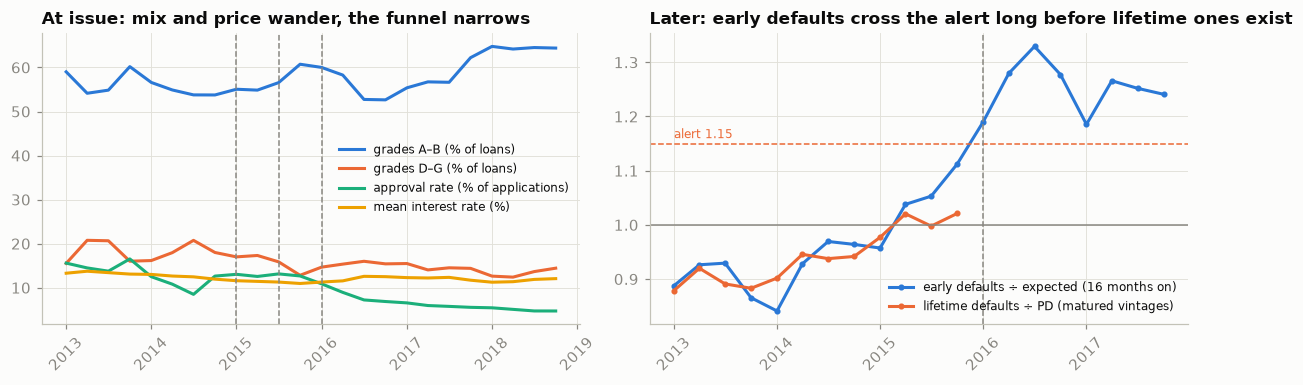

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
t_ = drift.index.to_timestamp()
ax = axes[0]
ax.plot(t_, drift["share A–B"] * 100, lw=2, color=SERIES[0], label="grades A–B (% of loans)")
ax.plot(t_, drift["share D–G"] * 100, lw=2, color=SERIES[1], label="grades D–G (% of loans)")
ax.plot(t_, drift["approval rate"] * 100, lw=2, color=SERIES[2], label="approval rate (% of applications)")
ax.plot(t_, drift["mean rate"] * 100, lw=2, color=SERIES[3], label="mean interest rate (%)")
for x_ in [TRAIN_END, VALID_END, TEST_END]:
    ax.axvline(x_, color=MUTED, ls="--", lw=1)
ax.set_title("At issue: mix and price wander, the funnel narrows"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ax.plot(t_, drift["EPD ÷ expected"], "-o", ms=3, lw=2, color=SERIES[0], label=f"early defaults ÷ expected ({EPD_MONTHS + 4} months on)")
ax.plot(t_, drift["default ÷ PD"], "-o", ms=3, lw=2, color=SERIES[1], label="lifetime defaults ÷ PD (matured vintages)")
ax.axhline(1, color=MUTED, lw=1); ax.axhline(EPD_ALERT, color=SERIES[1], ls="--", lw=1)
ax.text(t_[0], EPD_ALERT + 0.01, f"alert {EPD_ALERT}", color=SERIES[1], fontsize=8)
ax.axvline(TEST_END, color=MUTED, ls="--", lw=1)
ax.set_title("Later: early defaults cross the alert long before lifetime ones exist"); ax.legend(fontsize=8, loc="lower right"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
first_alert = drift.index[(drift["EPD ÷ expected"] > EPD_ALERT).fillna(False).values]
fy = pd.Series(X.fico.values).groupby(loans.issue_d.dt.year.values).median()
print(f"largest PSI over all quarters: score {drift['PSI score'].max():.3f} · FICO {drift['PSI fico'].max():.2f} "
      f"({drift['PSI fico'].idxmax()}) · purpose {drift['PSI purpose'].max():.2f} ({drift['PSI purpose'].idxmax()}) · "
      f"median FICO 2016 {fy[2016]:.0f}, 2018 {fy[2018]:.0f}")
print("early defaults ÷ expected, 2016–2017:", {str(k): round(v, 2) for k, v in drift.loc["2016Q1":"2017Q4", "EPD ÷ expected"].items()})
q16 = (qcode == 2016 * 4)
in_arrears = loans.loan_status.astype(str).isin(["In Grace Period", "Late (16-30 days)", "Late (31-120 days)"]).values
print(f"EPD share (early ÷ lifetime defaults, validation) {EPD_SHARE:.2f} · first vintage above the {EPD_ALERT} alert: "
      f"{first_alert.min() if len(first_alert) else 'none'} · 2016Q1 so far: {y[q16].mean():.1%} charged off, "
      f"{loans.is_open.values[q16].mean():.1%} still open, mean PD {pd_[q16].mean():.1%} → lifetime ÷ PD between "
      f"{y[q16].mean() / pd_[q16].mean():.2f} (no open loan defaults) and {(y[q16] | in_arrears[q16]).mean() / pd_[q16].mean():.2f} "
      f"(every loan now in arrears defaults) · peak early-default ratio {drift['EPD ÷ expected'].max():.2f} in {drift['EPD ÷ expected'].idxmax()}")

# Can the proxy stand in for the label? Re-level Trap 2's matured-only model (July 2017) with the early defaults it could see
stale_name = [n for n in refit_models if n.startswith("matured")][0]
stale = refit_models[stale_name]
p_stale = np.full(len(loans), np.nan)
k_stale = loans.epd.values[matured_then].sum() / y[matured_then].sum()
recent = ((loans.issue_d >= "2015-04-01") & (loans.issue_d < "2016-04-01")).values   # last four quarters with EPD visible then
p_stale[recent | te] = stale.predict_proba(X[recent | te])[:, 1]
relevel = loans.epd.values[recent].sum() / (k_stale * p_stale[recent]).sum()
print(f"July 2017, matured-only model on the 2015 H2 test vintage: predicted ÷ realised {p_stale[te].mean() / y[te].mean():.2f}; "
      f"early defaults of 2015Q2–2016Q1 run at {relevel:.2f}× its expectation; re-levelled: {relevel * p_stale[te].mean() / y[te].mean():.2f}")

This is Session 04's silent failure on a slower clock. At issue almost nothing moves: score PSI never exceeds 0.045, and FICO crosses the watch line only from late 2017 (peak 0.18 in 2018 Q1; purpose peaks at 0.11 in 2018 Q2) as the book moved up-market (median FICO 687 in 2016, 702 in 2018). Meanwhile early defaults ran above expectation: 1.19 for 2016 Q1, the first quarter over the 1.15 alert and readable from July 2017, and 1.33 for 2016 Q3. 2016 Q1's lifetime ratio, incomplete when the data ends, lies between 1.02 and 1.08: the proxy fired the right way two years early but overstated the size, because 2016 defaults came *earlier*. As a correction it overshoots: re-levelling Trap 2's July 2017 model by its early-default ratio (1.28) turns 0.87 into 1.11. An early proxy is a **trigger for review, not a substitute for the label**.

## 7 · Governance: fairness through proxies, and the reasons for a decline

*Part C · Productionise · package `slice_table`; the fairness slices and decline reasons E2 and S1 build on.*

Under the EU AI Act, systems "intended to be used to evaluate the creditworthiness of natural persons or establish their credit score" are high-risk, fraud detection excepted (Regulation (EU) 2024/1689, Annex III, point 5(b)); our reading is that the model card, gate and monitoring must evidence Articles 9–15. For this US data, the Equal Credit Opportunity Act and Regulation B require specific reasons for a refusal (12 CFR 1002.9) and forbid discrimination on race, colour, religion, national origin, sex, marital status and age, among other bases. None is in the data, so fairness is read through proxies (income band, state): questions, not findings.

In [16]:
dec_te = pd.DataFrame({"y": y[te], "approve": approve_model[te], "pd": pd_[te], "state": loans.addr_state.astype(str).values[te],
                       "income": pd.cut(loans.annual_inc.values[te], [-1, 40e3, 60e3, 90e3, 150e3, np.inf],
                                        labels=["below $40k", "$40–60k", "$60–90k", "$90–150k", "$150k or more"])})
def slice_table(g):
    return pd.Series({"loans": len(g), "approved": g.approve.mean(), "default if approved": g.y[g.approve].mean(),
                      "good loans declined": (~g.approve[g.y == 0]).mean(), "predicted ÷ realised": g.pd.mean() / g.y.mean()})
by_inc = dec_te.groupby("income", observed=True).apply(slice_table, include_groups=False)
by_state = dec_te.groupby("state").apply(slice_table, include_groups=False)
by_state = by_state[by_state.loans >= 1000]
ffmt = {"loans": "{:,.0f}", "approved": "{:.1%}", "default if approved": "{:.1%}", "good loans declined": "{:.1%}",
        "predicted ÷ realised": "{:.2f}"}
display(by_inc.style.format(ffmt))
display(by_state.sort_values("good loans declined").iloc[[0, 1, 2, -3, -2, -1]].style.format(ffmt))
print(f"{len(by_state)} states with ≥ 1,000 test loans · good-loan decline rate ranges "
      f"{by_state['good loans declined'].min():.1%} – {by_state['good loans declined'].max():.1%} · "
      f"calibration ranges {by_state['predicted ÷ realised'].min():.2f} – {by_state['predicted ÷ realised'].max():.2f}")

,loans,approved,default if approved,good loans declined,predicted ÷ realised
income,,,,,
below $40k,"33,924",77.9%,15.5%,18.4%,1.03
$40–60k,"44,409",88.7%,13.5%,9.0%,1.01
$60–90k,"44,447",93.3%,12.2%,5.2%,0.95
$90–150k,"30,519",96.2%,10.4%,2.8%,0.94
$150k or more,"8,937",97.2%,8.9%,2.0%,1.00


,loans,approved,default if approved,good loans declined,predicted ÷ realised
state,,,,,
MD,"3,736",91.4%,12.8%,5.9%,0.88
MA,"3,698",91.7%,11.7%,6.5%,0.98
CO,"3,393",91.1%,9.4%,6.8%,1.20
KS,"1,354",88.5%,10.9%,9.7%,1.17
AR,"1,214",88.3%,18.4%,9.8%,0.77
NV,"2,390",87.1%,14.9%,10.3%,0.91


33 states with ≥ 1,000 test loans · good-loan decline rate ranges 5.9% – 10.3% · calibration ranges 0.77 – 1.46


Calibration holds across income bands (0.94–1.03), yet errors do not fall evenly: the cut-off declines 18.4 % of *good* borrowers earning under $40k and 2.0 % of those over $150k. Income is a legitimate affordability factor but correlates with protected characteristics (task E2). Across the 33 states with ≥ 1,000 test loans, good-loan declines range from 5.9 % to 10.3 % and calibration from 0.77 to 1.46: partly noise, but worth a monitor.

A declined applicant is owed reasons. TreeSHAP splits each score into feature contributions; the four largest risk-increasing ones become the reasons:

In [17]:
# Reasons for a decline: per-applicant contributions (TreeSHAP in log-odds) for declined test applicants
REASON_TEXT = {"fico": "credit score", "loan_to_income": "amount requested relative to income", "annual_inc": "income",
               "dti": "debt-to-income ratio", "acc_open_past_24mths": "number of accounts opened in the last 24 months",
               "bc_open_to_buy": "unused card credit", "emp_length": "length of employment", "purpose": "purpose of the loan",
               "inq_last_6mths": "recent credit enquiries", "mths_since_recent_inq": "time since the last credit enquiry",
               "tot_hi_cred_lim": "total credit limits", "num_tl_op_past_12m": "accounts opened in the last 12 months",
               "credit_history_m": "length of credit history", "home_ownership": "housing status",
               "loan_amnt": "amount requested", "revol_util": "revolving credit utilisation", "mort_acc": "mortgage accounts"}
PROXY_RISK = {"purpose": "the codes 'wedding' and 'medical' can stand for marital status and health",
              "credit_history_m": "correlates with age", "emp_length": "correlates with age",
              "home_ownership": "correlates with age and family situation"}
rng = np.random.default_rng(SEED)
purpose_all = loans.purpose.astype(str).values
sensitive = np.isin(purpose_all, ["wedding", "medical"])
declined_idx = np.r_[rng.choice(np.flatnonzero(te & ~approve_model & ~sensitive), 2000, replace=False),
                     np.flatnonzero(te & ~approve_model & sensitive)]          # a random 2,000 plus every wedding/medical decline
contrib = model.predict(X.iloc[declined_idx], pred_contrib=True)[:, :-1]          # last column is the bias term
top4 = np.argsort(-contrib, axis=1)[:, :4]
reason_freq = pd.Series(np.array(FEATURES)[top4[:2000]].ravel()).value_counts().div(2000).head(10)
display(reason_freq.rename("share of declines with this in the top-4 reasons").to_frame()
        .assign(reason=lambda d: [REASON_TEXT.get(f, f) for f in d.index],
                proxy_risk=lambda d: [PROXY_RISK.get(f, "") for f in d.index])
        .style.format({"share of declines with this in the top-4 reasons": "{:.0%}"}))
has_purpose = (np.array(FEATURES)[top4] == "purpose").any(axis=1)
n_sens = len(declined_idx) - 2000
n_by = pd.Series(purpose_all[declined_idx[2000:]]).value_counts().to_dict()
print(f"declines whose top-4 reasons include the loan's purpose: {has_purpose[:2000].mean():.0%} of a random 2,000; "
      f"{has_purpose[2000:].mean():.0%} of all {n_sens} declined wedding or medical loans {n_by}")
i0 = declined_idx[0]
print(f"one declined applicant (PD {pd_[i0]:.1%}): " + "; ".join(REASON_TEXT.get(FEATURES[j], FEATURES[j]) for j in top4[0]))

,share of declines with this in the top-4 reasons,reason,proxy_risk
fico,69%,credit score,
dti,52%,debt-to-income ratio,
acc_open_past_24mths,50%,number of accounts opened in the last 24 months,
loan_to_income,43%,amount requested relative to income,
num_tl_op_past_12m,35%,accounts opened in the last 12 months,
annual_inc,24%,income,
bc_open_to_buy,17%,unused card credit,
emp_length,16%,length of employment,correlates with age
mths_since_recent_inq,13%,time since the last credit enquiry,
purpose,12%,purpose of the loan,the codes 'wedding' and 'medical' can stand for marital status and health


declines whose top-4 reasons include the loan's purpose: 12% of a random 2,000; 100% of all 348 declined wedding or medical loans {'medical': 348}
one declined applicant (PD 57.6%): number of accounts opened in the last 24 months; debt-to-income ratio; credit score; accounts opened in the last 12 months


The usual reasons are expected: credit score in 69 % of declines, DTI in 52 %, accounts opened in 24 months in 50 %, amount relative to income in 43 %. The warning sits lower: purpose is a top-4 reason in 12 % of random declines and in **practically every one** (100 % after rounding) of the 348 declined loans for medical bills, so a template letter would say *refused because the loan was for medical bills*. Health data under GDPR Article 9, or a proxy for a protected basis? S1's prohibited-reason check must catch it; E2 decides whether `purpose` stays.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/credit_risk/` (`features` with the 57-column whitelist, `train`, `calibrate`, `decide`, `monitor`); `POST /decision` returns PD, decision, price band, four reasons; compose with Postgres. |
| Monitoring (S04) | Per vintage quarter: approval rate (13.1 % → 4.7 %, 2015 Q3 to 2018 Q3); PSI on FICO, DTI, purpose, score; early defaults ÷ expected at 16 months (alert 1.15, first fired for 2016 Q1); good-loan declines by income and state; p95 latency. |
| CI/CD gate (S05) | Frozen holdout: Jul–Dec 2015, 162,236 matured loans, SHA-256 `7cc5b73cecfc`; AUC ≥ 0.68, predicted ÷ realised 0.90–1.10 (baseline 0.697, 0.99: PASS); whitelist test and leak scan. |
| MLflow tracking and registry (S06) | Vintage windows, whitelist hash `ca950881a399`, calibrator and curve, LGD 0.50, cost constants, cut-off (PD ≤ 24.9 %), reject-inference choice (none: approved population only). |
| Offline / online training and serving | Online decisioning; quarterly retraining on matured vintages (the freshest 41 months old); an ADR: an early-default alert triggers a review, not a re-level (0.87 → 1.11 overshoots). |
| Data and model drift | Default rates rose (13.2 % train, 15.1 % validation); rate grid, funnel and schema changed; score PSI ≤ 0.045 while 2016 early defaults ran 19–33 % above expectation: concept drift read from a proxy. |
| Knowledge base and context (S07–S09) | Policy from the data's history: FICO floor 660, DTI caps 24 → 39, purpose codes with validity dates, rate grid by quarter. Ablation: with and without policy-rule features. |
| GenAI and context engineering (S10–S11) | Reason letters from the top-4 TreeSHAP reasons and the policy text; a prohibited-reason check that catches `purpose`. |
| Governance | AI Act high-risk (Annex III 5(b)); ECOA/Regulation B reasons; fairness via proxies; CC0 with a take-down warning; free text and zip never loaded. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** `tests/test_features.py` fails on any column outside the whitelist; the leak scan in CI; grade and rate out; labels only from vintages matured at the training date; honest numbers on the frozen holdout.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `COST_OF_FUNDS` (2–8 %), `SERVICING_FEE` and `CHARGEOFF_LAG_M`; compare the profit-maximising cut-off with a loss budget; turn the band table into a price grid; write the ADR the committee signs.
- **C4 — Package, container, gate.** `src/credit_risk/` with `POST /decision`, a slim container, compose with Postgres, and `make ci` running the whitelist test and the gate on the fingerprinted holdout (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs logging what the spine table lists; `champion`/`challenger` aliases; a model card; a monitoring plan with the early-default alert, PSI, approval rate and fairness slices, quarterly retraining on matured vintages and a review when the alert fires twice running (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation.** The credit policy as a small graph from competency questions (which DTI cap applied in 2013? which purposes were valid in 2014?), with SHACL and validity dates; the model with and without policy-rule features on AUC, calibration and a renamed purpose code (Sessions 07–09).
- **E2 — Fairness and the regulatory position.** Error rates by income band and state with confidence intervals; whether `purpose`, `emp_length` and `credit_history_m` stay; the AI Act and GDPR Article 22 position, on one page.
- **E3 — The 60-month book as a monitoring problem.** Only vintages to 2013 Q4 have finished. Track the given model's predicted against realised default per vintage as it matures, and state when a five-year loan's label is mature enough to gate on.
- **E4 — Who never gets a label.** Rejected applicants have no outcome. Compare the rejected and accepted populations on the shared fields, state what the model cannot learn from this book, and price a small randomised approval band as a business decision in an ADR (no reject-inference modelling).

### Stretch

- **S1 — Reason letters (GenAI).** The adverse-action letter from the top-4 reasons and the written credit policy only (versioned prompt, structured output); a golden set of 50 declines checks every stated reason is the model's and no prohibited basis or proxy (purpose `medical`, age) appears; prompt-injection tests, cost per letter (Sessions 10–11).
- **S2 — Online decisioning and its cost.** `POST /decision` within a latency budget (the bureau call dominates) and a payment-event stream updating early defaults daily; cost per 1,000 applications.
- **S3 — A vintage dashboard.** Build the view the credit committee reads: realised against predicted default by vintage and months on book, immature vintages marked, and the alert that would have caught Trap 2's July 2017 level.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md` states the vintages, snapshot date and data source (Kaggle, CC0, the uploader's warning)
- [ ] Matured vintages only; whitelist test and leak scan in CI; traps removed
- [ ] Cut-off and price grid with the committee's ADR
- [ ] CI gate on the fingerprinted holdout; registered model, model card, monitoring plan
- [ ] Fairness slices, AI Act position, reasons for every decline
- [ ] One-page recommendation for the credit committee
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `duckdb`, `scikit-learn`, `lightgbm`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- George, N. (2019). *All Lending Club loan data*. Kaggle, CC0 (description retrieved through the Kaggle API; field definitions are on LendingClub's site, per the uploader).
- Regulation (EU) 2024/1689 (Artificial Intelligence Act), Annex III, point 5(b); Articles 9–15.
- Equal Credit Opportunity Act, 15 U.S.C. § 1691; Regulation B, 12 CFR § 1002.9.
- Zadrozny, B., Elkan, C. (2002). *Transforming classifier scores into accurate multiclass probability estimates.* KDD (isotonic calibration).
- Lundberg, S. M. et al. (2020). *From local explanations to global understanding with explainable AI for trees.* Nature Machine Intelligence, 2, 56–67 (TreeSHAP).
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (leakage), Ch. 8 (distribution shifts).

In [18]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"pyarrow {pa.__version__} · duckdb {duckdb.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · pyarrow 26.0.0 · duckdb 2.0.0
notebook finished · total wall time 300s
